# Muon with hybrid Newton-Schulz, as used to train DeepSeek-V4
### Notebook 3 of 9 on DeepSeek-V4 (technical report [arXiv:2606.19348](https://arxiv.org/abs/2606.19348), §2.4 Algorithm 1, §4.2.2)

AdamW updates every parameter with its own running estimate of scale, ignoring that most weights are matrices. Muon ([Jordan et al., 2024](https://kellerjordan.github.io/posts/muon/); [Liu et al., 2025](https://arxiv.org/abs/2502.16982)) instead replaces each matrix gradient's momentum with its **nearest orthogonal matrix**: all singular values set to 1, so the update moves every direction of the weight matrix by the same amount. The report uses it "for the majority of modules ... due to its faster convergence and improved training stability", with a modification: a **hybrid Newton-Schulz** orthogonalization of 10 iterations in two stages.

**The configuration in the report.** Muon momentum `μ = 0.95`, weight decay `0.1`, update RMS rescaled to `0.18` "for reutilization of our AdamW hyper-parameters" (§4.2.2); Newton-Schulz coefficients `(3.4445, −4.7750, 2.0315)` for 8 iterations, then `(2, −1.5, 0.5)` for 2; AdamW (`β = (0.9, 0.95)`, `ε = 1e-20`, weight decay 0.1) for the embedding, the prediction head, RMSNorm weights and (per §2.4) the static biases and gates of mHC; **no QK-Clip**, because RMSNorm on queries and keys already bounds the attention logits. Peak learning rates are `2.7e-4` (Flash) and `2.0e-4` (Pro). We did not train V4; we build the optimizer and test each claim at toy scale.

| section | question | number it carries |
|---|---|---|
| 1 | What does "nearest orthogonal matrix" mean? | singular values `(3, 1) → (1, 1)` |
| 2 | Why two sets of Newton-Schulz coefficients? | error after 8 and after 10 iterations |
| 3 | Algorithm 1 in PyTorch | update RMS = 0.18 |
| 4 | Why is QK-Clip unnecessary here? | bound on attention logits |
| 5 | Muon vs AdamW on a toy problem | final loss, same learning rates |

In [1]:
import math, time, itertools
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 105, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25, "font.size": 9})
CHECKS = []
def check(name, ok, detail=""): CHECKS.append((name, bool(ok), detail)); print(("PASS " if ok else "FAIL ") + name + (f"   [{detail}]" if detail else ""))

## Orthogonalizing a matrix

Take `M = [[3, 0], [0, 1]]`. It stretches one direction three times more than the other. Its singular value decomposition is `M = UΣVᵀ` with `Σ = diag(3, 1)`. The **orthogonalization** of `M` is `UVᵀ`, here the identity: same directions, all singular values 1. Applied to a gradient-momentum matrix this means the update can no longer be dominated by a few large singular directions, which is the intuition for Muon's faster progress on ill-conditioned problems. In general `UVᵀ = M (MᵀM)^(-1/2)`, and computing an SVD at every step is too slow on accelerators.

**Newton-Schulz** iterations approximate `UVᵀ` with matrix multiplications only. First normalize `M₀ = M/‖M‖_F`, which puts every singular value in `(0, 1]`. Then iterate (the report's Eq. 28)

`M_k = a·M_{k-1} + b·(M_{k-1} M_{k-1}ᵀ) M_{k-1} + c·(M_{k-1} M_{k-1}ᵀ)² M_{k-1}`

which acts on each singular value `σ` as the scalar polynomial `p(σ) = aσ + bσ³ + cσ⁵`, leaving `U` and `V` untouched. Iterating `p` pushes every `σ` toward a fixed point at 1.

In [2]:
def newton_schulz(M, steps_coeffs):
    """steps_coeffs: list of (a,b,c), one per iteration.  Returns the approximately orthogonalised matrix (shape preserved)."""
    X = M / (M.norm() + 1e-7)                                  # Frobenius-normalise: every singular value in (0,1]
    tall = X.shape[0] > X.shape[1]
    if tall: X = X.T                                           # work with the short side for the Gram matrix
    for a, b, c in steps_coeffs:
        A = X @ X.T
        X = a * X + (b * A + c * A @ A) @ X
    return X.T if tall else X

M = torch.tensor([[3., 0.], [0., 1.]]); U, S, Vh = torch.linalg.svd(M)
print("singular values of M:", S.tolist(), "-> of U V^T:", torch.linalg.svdvals(U @ Vh).tolist())
HYBRID = [(3.4445, -4.7750, 2.0315)] * 8 + [(2.0, -1.5, 0.5)] * 2                       # the report's schedule
O = newton_schulz(M, HYBRID); print("Newton-Schulz (hybrid, 10 steps) singular values:", torch.linalg.svdvals(O).numpy().round(4))
check("the orthogonalisation of diag(3,1) has singular values (1,1)", torch.allclose(torch.linalg.svdvals(U @ Vh), torch.ones(2)))
check("hybrid Newton-Schulz brings both singular values of diag(3,1) to within 0.01 of 1", (torch.linalg.svdvals(O) - 1).abs().max() < 0.01)
torch.manual_seed(0); G = torch.randn(64, 128); Ou = newton_schulz(G, HYBRID); Us, _, Vs = torch.linalg.svd(G, full_matrices=False)
check("on a random 64x128 matrix the iteration agrees with the SVD-based U V^T up to the residual singular-value error", (Ou - Us @ Vs).abs().mean() < 0.02, f"mean abs err {(Ou - Us @ Vs).abs().mean():.4f}")

singular values of M: [3.0, 1.0] -> of U V^T: [1.0, 1.0]
Newton-Schulz (hybrid, 10 steps) singular values: [1.0005 1.0002]
PASS the orthogonalisation of diag(3,1) has singular values (1,1)
PASS hybrid Newton-Schulz brings both singular values of diag(3,1) to within 0.01 of 1
PASS on a random 64x128 matrix the iteration agrees with the SVD-based U V^T up to the residual singular-value error   [mean abs err 0.0000]


## Why two sets of coefficients

The scalar map `p(σ) = aσ + bσ³ + cσ⁵` has to do two jobs. It has to move *small* singular values up quickly (a gradient's singular values span orders of magnitude, and after Frobenius normalization many are tiny), and it has to *settle* at 1. These pull against each other. The first stage, `(3.4445, −4.7750, 2.0315)`, multiplies small `σ` by about 3.44 per step but has slope `p'(1) = a + 3b + 5c = −0.72` at 1, so it overshoots and oscillates around 1 instead of converging. The second stage, `(2, −1.5, 0.5)`, has `p'(1) = 2 − 4.5 + 2.5 = 0`: a flat fixed point, so errors near 1 shrink quadratically. The report's recipe, "8 steps for fast convergence ... 2 steps to stabilize singular values at 1", uses one then the other. We check each claim numerically.

p'(1): stage 1 = -0.723   stage 2 = 0.000
PASS stage 2 has a flat fixed point at 1 (p(1) = 1, p'(1) = 0); stage 1 does not   [-0.723, 0.0e+00]


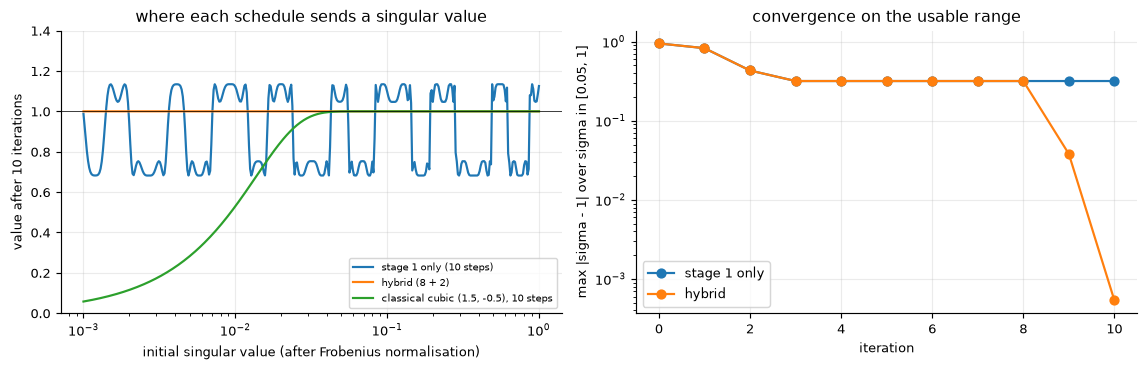

max |sigma-1| for sigma in [0.05,1]:  after 8 stage-1 steps 0.318;  after the 2 stabilising steps 0.0005;  stage 1 alone for 10 steps 0.318
all lifted
PASS after 8 fast steps singular values (>=0.05) are within 0.5 of 1 but not converged; the 2 stabilising steps cut the error by >10x   [0.318 -> 0.0005]
PASS the hybrid schedule beats 10 stage-1 steps at settling on 1
sigma0 = 0.005 after 10 steps:  hybrid 1.000   classical cubic 0.282
PASS for a small singular value (0.005) the hybrid schedule reaches ~1 in 10 steps while the classical cubic is still below 0.9


In [3]:
p = lambda s, a, b, c: a * s + b * s ** 3 + c * s ** 5
A1, A2 = (3.4445, -4.7750, 2.0315), (2.0, -1.5, 0.5)
d1 = A1[0] + 3 * A1[1] + 5 * A1[2]; d2 = A2[0] + 3 * A2[1] + 5 * A2[2]
print(f"p'(1): stage 1 = {d1:.3f}   stage 2 = {d2:.3f}")
check("stage 2 has a flat fixed point at 1 (p(1) = 1, p'(1) = 0); stage 1 does not", abs(p(1., *A2) - 1) < 1e-9 and abs(d2) < 1e-9 and abs(d1) > 0.5, f"{d1:.3f}, {d2:.1e}")
s = torch.logspace(-3, 0, 400); traj = {"stage 1 only (10 steps)": [s.clone()], "hybrid (8 + 2)": [s.clone()]}
x1 = s.clone(); x2 = s.clone()
for i in range(10):
    x1 = p(x1, *A1); x2 = p(x2, *(A1 if i < 8 else A2)); traj["stage 1 only (10 steps)"].append(x1.clone()); traj["hybrid (8 + 2)"].append(x2.clone())
classical = s.clone(); cl = [s.clone()]
for _ in range(10): classical = 1.5 * classical - 0.5 * classical ** 3; cl.append(classical.clone())
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for k, v in [("stage 1 only (10 steps)", traj["stage 1 only (10 steps)"]), ("hybrid (8 + 2)", traj["hybrid (8 + 2)"]), ("classical cubic (1.5, -0.5), 10 steps", cl)]:
    axs[0].semilogx(s, v[-1], label=k)
axs[0].axhline(1, color="k", lw=.5); axs[0].set_xlabel("initial singular value (after Frobenius normalisation)"); axs[0].set_ylabel("value after 10 iterations"); axs[0].legend(fontsize=7); axs[0].set_ylim(0, 1.4); axs[0].set_title("where each schedule sends a singular value")
for k, v in [("stage 1 only", traj["stage 1 only (10 steps)"]), ("hybrid", traj["hybrid (8 + 2)"])]:
    err = torch.stack([(t[(s > 0.05)] - 1).abs().max() for t in v]); axs[1].semilogy(err, "o-", label=k)
axs[1].set_xlabel("iteration"); axs[1].set_ylabel("max |sigma - 1| over sigma in [0.05, 1]"); axs[1].legend(); axs[1].set_title("convergence on the usable range")
plt.tight_layout(); plt.show()
e8 = (traj["hybrid (8 + 2)"][8][s > 0.05] - 1).abs().max().item(); e10 = (traj["hybrid (8 + 2)"][10][s > 0.05] - 1).abs().max().item(); e10_stage1 = (traj["stage 1 only (10 steps)"][10][s > 0.05] - 1).abs().max().item()
print(f"max |sigma-1| for sigma in [0.05,1]:  after 8 stage-1 steps {e8:.3f};  after the 2 stabilising steps {e10:.4f};  stage 1 alone for 10 steps {e10_stage1:.3f}")
lo = s[(traj["hybrid (8 + 2)"][10] < 0.5)]; print(f"singular values that the hybrid schedule does NOT lift above 0.5 in 10 steps: those below {lo.max():.1e}" if len(lo) else "all lifted")
check("after 8 fast steps singular values (>=0.05) are within 0.5 of 1 but not converged; the 2 stabilising steps cut the error by >10x", e8 > 0.05 and e10 < e8 / 10, f"{e8:.3f} -> {e10:.4f}")
check("the hybrid schedule beats 10 stage-1 steps at settling on 1", e10 < e10_stage1)
i5 = (s - 0.005).abs().argmin(); print(f"sigma0 = 0.005 after 10 steps:  hybrid {traj['hybrid (8 + 2)'][-1][i5]:.3f}   classical cubic {cl[-1][i5]:.3f}")
check("for a small singular value (0.005) the hybrid schedule reaches ~1 in 10 steps while the classical cubic is still below 0.9", traj["hybrid (8 + 2)"][-1][i5] > 0.8 and cl[-1][i5] < 0.9)

**What we found.** The fast stage alone leaves singular values scattered around 1 (it oscillates), the two stabilizing steps with the flat fixed point shrink that error by more than an order of magnitude, and the classical cubic `(1.5, −0.5)` is slower at lifting small singular values (a singular value starting at 0.005 is still below 0.9 after 10 classical steps, against about 1 for the hybrid schedule). The schedule is a **bounded-effort approximation**, not an exact orthogonalization: singular values below roughly `1e-3` of the largest are not lifted to 1 (printed above), so the "orthogonal" update still carries information about how ill-conditioned the gradient was. The report does not ablate the coefficient schedule against alternatives in the sections we read, so we cannot say how much the hybrid contributes to V4's training stability on its own.

Now the optimizer around it.

## Algorithm 1 in PyTorch

The report's Algorithm 1, for each logically independent weight `W ∈ R^{n×m}`:

```
G_t  = ∇_W L_t(W_{t-1})
M_t  = μ M_{t-1} + G_t                       # momentum buffer
O'_t = HybridNewtonSchulz(μ M_t + G_t)       # Nesterov trick, then orthogonalise
O_t  = O'_t · sqrt(max(n, m)) · γ            # rescale the update RMS
W_t  = W_{t-1} (1 − ηλ) − η O_t              # decoupled weight decay + update
```

The rescale is the part that makes Muon a drop-in: an orthogonalized `n × m` matrix has Frobenius norm `sqrt(min(n,m))`, hence entry RMS `1/sqrt(max(n,m))`; multiplying by `sqrt(max(n,m))·γ` makes the RMS equal to `γ` for every matrix shape. With `γ = 0.18` the update RMS matches what AdamW typically produces, so one set of learning rates and weight decays serves both optimizers.

In [4]:
class Muon(torch.optim.Optimizer):
    def __init__(self, params, lr, momentum=0.95, weight_decay=0.1, gamma=0.18, coeffs=HYBRID):
        super().__init__(params, dict(lr=lr, momentum=momentum, weight_decay=weight_decay, gamma=gamma)); self.coeffs = coeffs
    @torch.no_grad()
    def step(self):
        for g in self.param_groups:
            for W in g["params"]:
                if W.grad is None: continue
                st = self.state[W]; M = st.setdefault("M", torch.zeros_like(W))
                M.mul_(g["momentum"]).add_(W.grad)                                      # M_t = mu M_{t-1} + G_t
                O = newton_schulz(g["momentum"] * M + W.grad, self.coeffs)              # Nesterov + hybrid Newton-Schulz
                O = O * math.sqrt(max(W.shape)) * g["gamma"]                            # rescale RMS to gamma
                W.mul_(1 - g["lr"] * g["weight_decay"]).add_(O, alpha=-g["lr"])         # decoupled weight decay, then update
                st["last_update_rms"] = O.pow(2).mean().sqrt().item()

for shape in [(256, 256), (64, 512), (1024, 128)]:
    W = nn.Parameter(torch.randn(*shape) * .02); W.grad = torch.randn(*shape); opt = Muon([W], lr=1e-3); opt.step()
    print(f"{str(shape):>12s}: update RMS = {opt.state[W]['last_update_rms']:.3f}")
    check(f"update RMS for a {shape} matrix is ~0.18 (within 15%) regardless of shape", abs(opt.state[W]["last_update_rms"] - 0.18) < 0.027, f"{opt.state[W]['last_update_rms']:.3f}")
# weight decay and the update, written out: one step on a known matrix
W = nn.Parameter(torch.eye(4) * 2.0); W.grad = torch.randn(4, 4); w0 = W.detach().clone(); opt = Muon([W], lr=0.1, weight_decay=0.5); opt.step()
O = newton_schulz(0.95 * W.grad + W.grad, HYBRID) * math.sqrt(4) * 0.18
check("one Muon step equals W(1 - lr*wd) - lr*O computed by hand (first step: M = G)", torch.allclose(W, w0 * (1 - 0.1 * 0.5) - 0.1 * O, atol=1e-5))

def split_params(model):
    """AdamW for embeddings, the output head, norm weights and 1-D parameters; Muon for the remaining matrices (report §2.4)."""
    muon, adam = [], []
    for n_, p_ in model.named_parameters():
        (adam if (p_.ndim < 2 or any(k in n_ for k in ("emb", "head", "norm"))) else muon).append(p_)
    return muon, adam
class Tiny(nn.Module):
    def __init__(s): super().__init__(); s.emb = nn.Embedding(10, 8); s.fc = nn.Linear(8, 8); s.norm = nn.LayerNorm(8); s.head = nn.Linear(8, 10)
mu_, ad_ = split_params(Tiny()); print("Muon gets", len(mu_), "tensors (the 8x8 matrix), AdamW gets", len(ad_))
check("the parameter split sends only the hidden 2-D weight matrix to Muon", len(mu_) == 1 and mu_[0].shape == (8, 8))

  (256, 256): update RMS = 0.180
PASS update RMS for a (256, 256) matrix is ~0.18 (within 15%) regardless of shape   [0.180]
   (64, 512): update RMS = 0.180
PASS update RMS for a (64, 512) matrix is ~0.18 (within 15%) regardless of shape   [0.180]
 (1024, 128): update RMS = 0.180
PASS update RMS for a (1024, 128) matrix is ~0.18 (within 15%) regardless of shape   [0.180]
PASS one Muon step equals W(1 - lr*wd) - lr*O computed by hand (first step: M = G)
Muon gets 1 tensors (the 8x8 matrix), AdamW gets 6
PASS the parameter split sends only the hidden 2-D weight matrix to Muon


## Why QK-Clip is not needed

Muon's updates can grow weight matrices quickly, and in attention that can blow up the logits `q·k`. [Liu et al., 2025](https://arxiv.org/abs/2502.16982) therefore add **QK-Clip**, which rescales the query and key projections when the largest logit exceeds a threshold. V4 does not need it because it applies an RMSNorm to every query head and to the compressed KV entry just before attention (notebook 1). After RMSNorm without a learned scale a vector of dimension `c` has norm `√c`, so by Cauchy-Schwarz `|q·k|/√c ≤ √c·√c/√c = √c`, **whatever the weights are**.

In [5]:
def rms(x, eps=1e-6): return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + eps)
torch.manual_seed(0); c = 512; Wq = torch.randn(64, c) * 1e3; Wk = torch.randn(64, c) * 1e3            # absurdly large projection weights (a runaway optimizer)
h = torch.randn(100, 64); q, k = h @ Wq, h @ Wk
raw = (q @ k.T / math.sqrt(c)).abs().max().item(); normed = (rms(q) @ rms(k).T / math.sqrt(c)).abs().max().item()
print(f"max |logit| with weights of scale 1e3:  without RMSNorm {raw:.3e}   with RMSNorm {normed:.2f}   (bound sqrt(c) = {math.sqrt(c):.2f})")
check("RMSNorm on q and k bounds every attention logit by sqrt(c), however large the weights", normed <= math.sqrt(c) + 1e-3)
check("without the norm the same weights give logits >1e6 times larger", raw > 1e6 * normed)

max |logit| with weights of scale 1e3:  without RMSNorm 2.838e+08   with RMSNorm 3.65   (bound sqrt(c) = 22.63)
PASS RMSNorm on q and k bounds every attention logit by sqrt(c), however large the weights
PASS without the norm the same weights give logits >1e6 times larger


The bound is on the *logits*. It does not say the weights stay well behaved, and it only applies because every attention variant in V4 normalizes before the dot product; a different architecture would still need QK-Clip.

## Muon against AdamW on a toy problem

Finally, a sanity check of the optimizer. We train a 3-layer MLP student to match a fixed random teacher (regression, 32 → 128 → 128 → 16), with matrices updated by either AdamW or Muon (biases always AdamW), at the *same* learning rates, because the `γ = 0.18` rescale is meant to make them comparable. This is a small, smooth, well-conditioned problem, nothing like a trillion-parameter language model, so what it shows is limited to "the implementation works and behaves sensibly".

optimizer     lr=0.001     lr=0.003      lr=0.01
adamw          0.0005       0.0005       0.0005    (full-data MSE after 400 steps; the initial MSE is 0.043)
muon           0.0004       0.0002       0.0002    (full-data MSE after 400 steps; the initial MSE is 0.043)


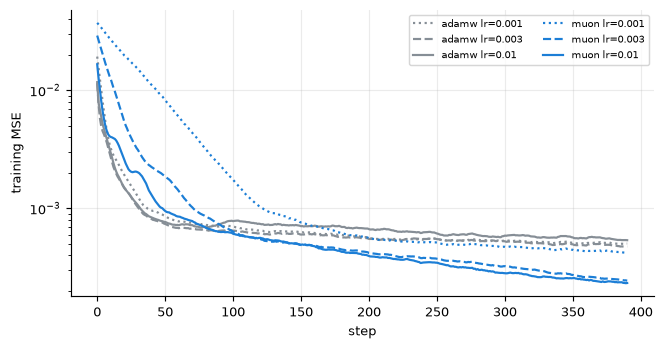

PASS both optimizers fit the teacher far below the initial loss (best final MSE < 10% of initial)   [adamw 0.0005, muon 0.0002]
best final MSE over the 3 learning rates:  AdamW 0.0005   Muon 0.0002   (Muon lower, one seed)


In [6]:
def run(opt_name, lr, steps=400, seed=0):
    torch.manual_seed(seed); T = nn.Sequential(nn.Linear(32, 128), nn.Tanh(), nn.Linear(128, 128), nn.Tanh(), nn.Linear(128, 16))
    S = nn.Sequential(nn.Linear(32, 128), nn.Tanh(), nn.Linear(128, 128), nn.Tanh(), nn.Linear(128, 16)); X = torch.randn(4096, 32); Y = T(X).detach()
    mats = [p for p in S.parameters() if p.ndim == 2]; vecs = [p for p in S.parameters() if p.ndim < 2]
    opts = [torch.optim.AdamW(vecs, lr=lr, betas=(0.9, 0.95), weight_decay=0.1)]
    opts.append(Muon(mats, lr=lr, weight_decay=0.1) if opt_name == "muon" else torch.optim.AdamW(mats, lr=lr, betas=(0.9, 0.95), weight_decay=0.1))
    losses = []
    for s in range(steps):
        idx = torch.randint(0, 4096, (256,)); loss = F.mse_loss(S(X[idx]), Y[idx]); [o.zero_grad() for o in opts]; loss.backward(); [o.step() for o in opts]; losses.append(loss.item())
    return np.array(losses), F.mse_loss(S(X), Y).item()
LRS = [1e-3, 3e-3, 1e-2]; R = {(o, lr): run(o, lr) for o in ["adamw", "muon"] for lr in LRS}
print(f"{'optimizer':8s} " + " ".join(f"lr={lr:g}".rjust(12) for lr in LRS))
for o in ["adamw", "muon"]: print(f"{o:8s} " + " ".join(f"{R[(o, lr)][1]:12.4f}" for lr in LRS), "   (full-data MSE after 400 steps; the initial MSE is", f"{R[(o, 1e-3)][0][0]:.3f})")
fig, ax = plt.subplots(figsize=(6.4, 3.4))
for o, col in [("adamw", "#868e96"), ("muon", "#1c7ed6")]:
    for lr, ls in zip(LRS, [":", "--", "-"]): ax.semilogy(np.convolve(R[(o, lr)][0], np.ones(10) / 10, mode="valid"), color=col, ls=ls, label=f"{o} lr={lr:g}")
ax.set_xlabel("step"); ax.set_ylabel("training MSE"); ax.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()
best = {o: min(R[(o, lr)][1] for lr in LRS) for o in ["adamw", "muon"]}
check("both optimizers fit the teacher far below the initial loss (best final MSE < 10% of initial)", all(best[o] < 0.1 * R[("adamw", 1e-3)][0][0] for o in best), f"adamw {best['adamw']:.4f}, muon {best['muon']:.4f}")
print(f"best final MSE over the 3 learning rates:  AdamW {best['adamw']:.4f}   Muon {best['muon']:.4f}   ({'Muon lower' if best['muon'] < best['adamw'] else 'AdamW lower'}, one seed)")

**What we found** is the table above, and we make no ranking claim from it: one seed, one small problem, and three learning rates. What the toy supports is that our Muon implementation trains, that the same learning rates are in a sensible range for both optimizers (the point of the RMS rescale), and that the update RMS really is 0.18 for every matrix shape.

## Closing thoughts

Muon's history is short: introduced as a practical optimizer for hidden-layer matrices in 2024, scaled with weight decay and the RMS-matching trick by Liu et al. (2025), and run by V4 at 1.6T parameters with a hybrid iteration that trades a small residual singular-value error for ten matrix multiplications per matrix per step. In our checks the pieces behave as the report describes: the second coefficient set has a flat fixed point at 1; the schedule settles the usable singular values and leaves the tiny ones; the rescale gives a shape-independent update RMS; and RMSNorm on `q` and `k` bounds the logits, which is why QK-Clip is not needed.

**What is open.** The report gives no ablation of the hybrid schedule against alternatives, and none of AdamW versus Muon at V4's scale in the sections we read, so the claim of "faster convergence and improved training stability" is the authors' and we did not test it at scale. It also lists the mHC static biases and gates under AdamW in §2.4 but not in §4.2.2, an inconsistency we flag rather than resolve. The distributed side, ZeRO with whole-matrix updates, is the subject of notebook 9.

**Next.** Notebook 4 covers V4's changes to the mixture-of-experts layer.

Credits: Muon is due to Keller Jordan and collaborators; the scaling recipe to Liu et al. (Moonshot AI); the hybrid schedule and everything about V4 to DeepSeek-AI.

In [7]:
print(f"{'#':>2s}  {'status':6s}  check")
for i, (n_, ok, d_) in enumerate(CHECKS, 1): print(f"{i:2d}  {'PASS' if ok else 'FAIL':6s}  {n_}")
failed = [n_ for n_, ok, _ in CHECKS if not ok]; print(f"\n{len(CHECKS) - len(failed)} passed, {len(failed)} failed")
assert not failed, failed

 #  status  check
 1  PASS    the orthogonalisation of diag(3,1) has singular values (1,1)
 2  PASS    hybrid Newton-Schulz brings both singular values of diag(3,1) to within 0.01 of 1
 3  PASS    on a random 64x128 matrix the iteration agrees with the SVD-based U V^T up to the residual singular-value error
 4  PASS    stage 2 has a flat fixed point at 1 (p(1) = 1, p'(1) = 0); stage 1 does not
 5  PASS    after 8 fast steps singular values (>=0.05) are within 0.5 of 1 but not converged; the 2 stabilising steps cut the error by >10x
 6  PASS    the hybrid schedule beats 10 stage-1 steps at settling on 1
 7  PASS    for a small singular value (0.005) the hybrid schedule reaches ~1 in 10 steps while the classical cubic is still below 0.9
 8  PASS    update RMS for a (256, 256) matrix is ~0.18 (within 15%) regardless of shape
 9  PASS    update RMS for a (64, 512) matrix is ~0.18 (within 15%) regardless of shape
10  PASS    update RMS for a (1024, 128) matrix is ~0.18 (within 15%) regardle